# checkmodel quickstart

Diagnose a linear regression, a logistic regression and compare models, the way R's `performance` package does it.

In [1]:
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

from checkmodel import (
    check_collinearity,
    check_model,
    check_normality,
    compare_performance,
    model_performance,
    r2,
)

mtcars = pd.read_csv("../tests/data/mtcars.csv", index_col=0)
mtcars.head()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2


## Check a linear model

`check_model()` runs every check that applies to an OLS fit and prints one line per check.

In [2]:
fit = smf.ols("mpg ~ wt + hp", data=mtcars).fit()
report = check_model(fit)
report

# Model checks: OLS (gaussian, identity link), n = 32

Normality of residuals: Warning: Non-normality of residuals detected (p = 0.021).
Homogeneity of variance: OK: Error variance appears to be homoscedastic (p = 0.402).
Collinearity: OK: Low collinearity (all VIF < 5; max 1.77).
Influential observations: OK: No outliers detected (Cook's distance > 0.808).
Autocorrelation: Warning: Autocorrelated residuals detected (p = 0.041).

All diagnostics in one figure. Each subtitle says what a good model looks like.

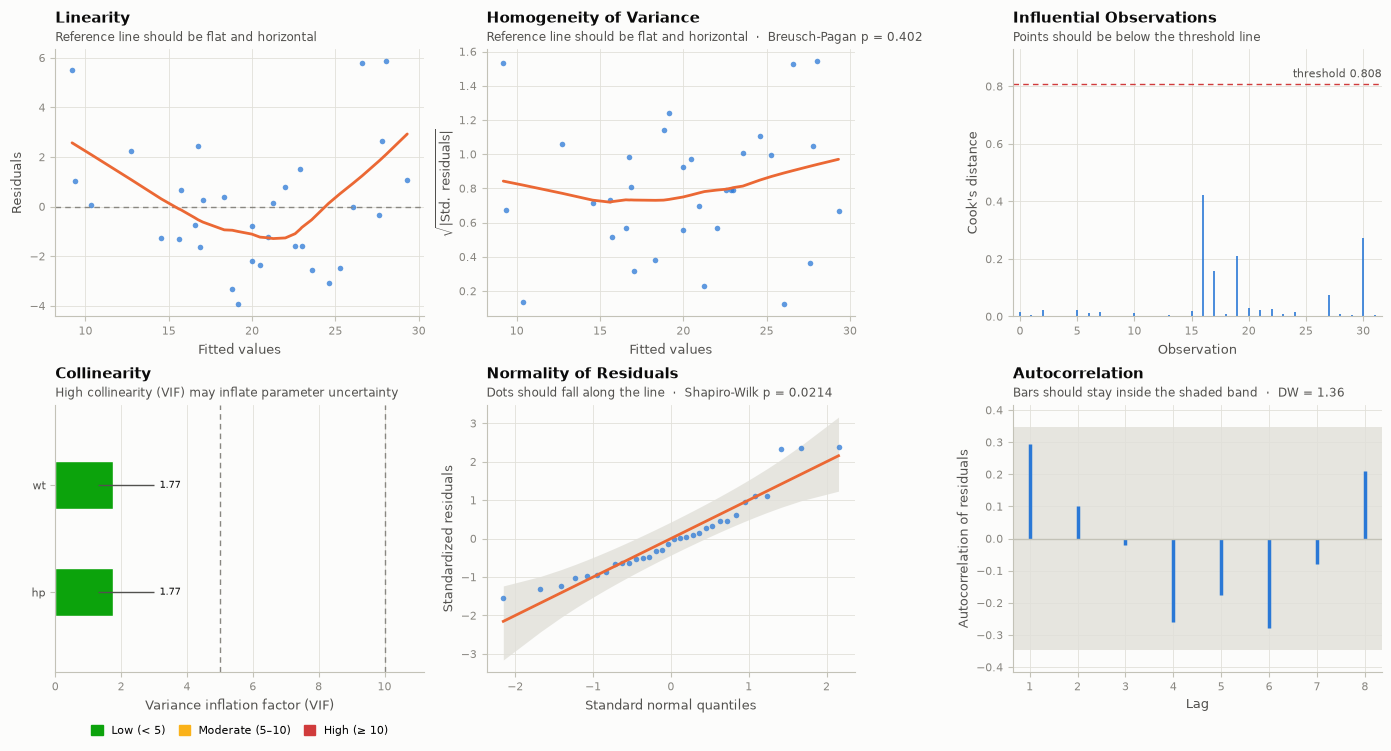

In [3]:
report.plot();

The report behaves like a dictionary of results, each with `.passed`, `.statistic`, `.p_value`, `.plot()` and `.to_dataframe()`.

In [4]:
report.summary()

,Check,Method,Statistic,p,Passed,Message
check,,,,,,
normality,Normality of residuals,Shapiro-Wilk,0.920484,0.021429,False,Warning: Non-normality of residuals detected (...
heteroscedasticity,Homogeneity of variance,Breusch-Pagan,0.701202,0.402380,True,OK: Error variance appears to be homoscedastic...
collinearity,Collinearity,Variance inflation factor,1.766625,NaN,True,OK: Low collinearity (all VIF < 5; max 1.77).
outliers,Influential observations,Cook's distance > F median,0.423611,NaN,True,OK: No outliers detected (Cook's distance > 0....
autocorrelation,Autocorrelation,Durbin-Watson (exact),1.362399,0.041225,False,Warning: Autocorrelated residuals detected (p ...


In [5]:
normality = report["normality"]
normality.method, normality.statistic, normality.p_value

('Shapiro-Wilk', 0.9204843530557756, 0.02142904232604338)

In [6]:
check_normality(fit).plot();

## Collinearity

Adding correlated predictors inflates the variance of the estimates.

In [7]:
wide = smf.ols("mpg ~ wt + hp + disp + cyl", data=mtcars).fit()
vif = check_collinearity(wide)
print(vif)
vif.to_dataframe()

,Term,VIF,VIF_CI_low,VIF_CI_high,SE_factor,Tolerance,Tolerance_CI_low,Tolerance_CI_high
0,wt,4.848016,3.093746,8.072120,2.201821,0.206270,0.123883,0.323233
1,hp,3.405983,2.255343,5.611289,1.845530,0.293601,0.178212,0.443391
2,disp,10.373286,6.314909,17.530574,3.220759,0.096401,0.057043,0.158355
3,cyl,6.737707,4.194743,11.304828,2.595709,0.148418,0.088458,0.238394


In [8]:
vif.plot();

## scikit-learn

scikit-learn estimators don't store their training data, so pass `X` and `y`. The results match the statsmodels fit.

In [9]:
from sklearn.linear_model import LinearRegression

X, y = mtcars[["wt", "hp"]], mtcars["mpg"]
model = LinearRegression().fit(X, y)
check_model(model, X=X, y=y)

# Model checks: LinearRegression (gaussian, identity link), n = 32

Normality of residuals: Warning: Non-normality of residuals detected (p = 0.021).
Homogeneity of variance: OK: Error variance appears to be homoscedastic (p = 0.402).
Collinearity: OK: Low collinearity (all VIF < 5; max 1.77).
Influential observations: OK: No outliers detected (Cook's distance > 0.808).
Autocorrelation: Warning: Autocorrelated residuals detected (p = 0.041).

## Logistic regression

Normality and homoscedasticity are not expected for a binary outcome; binned residuals are checked instead.

In [10]:
logit = smf.glm("vs ~ mpg + wt", data=mtcars, family=sm.families.Binomial()).fit()
logit_report = check_model(logit)
logit_report

# Model checks: GLM (binomial, logit link), n = 32

Collinearity: OK: Low collinearity (all VIF < 5; max 2.63).
Influential observations: OK: No outliers detected (Cook's distance > 0.709).
Binned residuals: Warning: Probably bad model fit. Only about 50% of the residuals are inside the error bounds.

In [11]:
logit_report.plot();

## Performance metrics

In [12]:
r2(fit)

# R2 for Linear Regression
       R2: 0.827
  adj. R2: 0.815

In [13]:
model_performance(fit)

,AIC,AICc,BIC,R2,R2_adjusted,RMSE,Sigma
0,156.652339,158.13382,162.515282,0.826785,0.81484,2.468854,2.593412


In [14]:
model_performance(logit)

,AIC,AICc,BIC,R2_Tjur,RMSE,Sigma,Log_loss,Score_log,Score_spherical,PCP
0,31.297876,32.155018,35.695083,0.477693,0.359477,1.0,0.395279,-14.902937,0.09458,0.742927


## Compare models

Keyword names label the rows. With `rank=True` the models are sorted by a combined performance score.

In [15]:
small = smf.ols("mpg ~ wt", data=mtcars).fit()
large = smf.ols("mpg ~ wt + hp + qsec", data=mtcars).fit()
compare_performance(small=small, medium=fit, large=large)

,Name,Model,AIC,AIC_wt,AICc,AICc_wt,BIC,BIC_wt,R2,R2_adjusted,RMSE,Sigma
0,small,OLS,166.029429,0.005135,166.886572,0.008214,170.426637,0.013722,0.752833,0.744594,2.949163,3.045882
1,medium,OLS,156.652339,0.558099,158.133820,0.653453,162.515282,0.716740,0.826785,0.814840,2.468854,2.593412
2,large,OLS,157.142611,0.436767,159.450303,0.338333,164.471290,0.269538,0.834768,0.817064,2.411297,2.577785


In [16]:
compare_performance(small=small, medium=fit, large=large, rank=True)

,Name,Model,R2,R2_adjusted,RMSE,Sigma,AIC_wt,AICc_wt,BIC_wt,Performance_Score
0,medium,OLS,0.826785,0.814840,2.468854,2.593412,0.558099,0.653453,0.716740,0.961641
1,large,OLS,0.834768,0.817064,2.411297,2.577785,0.436767,0.338333,0.269538,0.808012
2,small,OLS,0.752833,0.744594,2.949163,3.045882,0.005135,0.008214,0.013722,0.000000
